In [1]:
%matplotlib widget

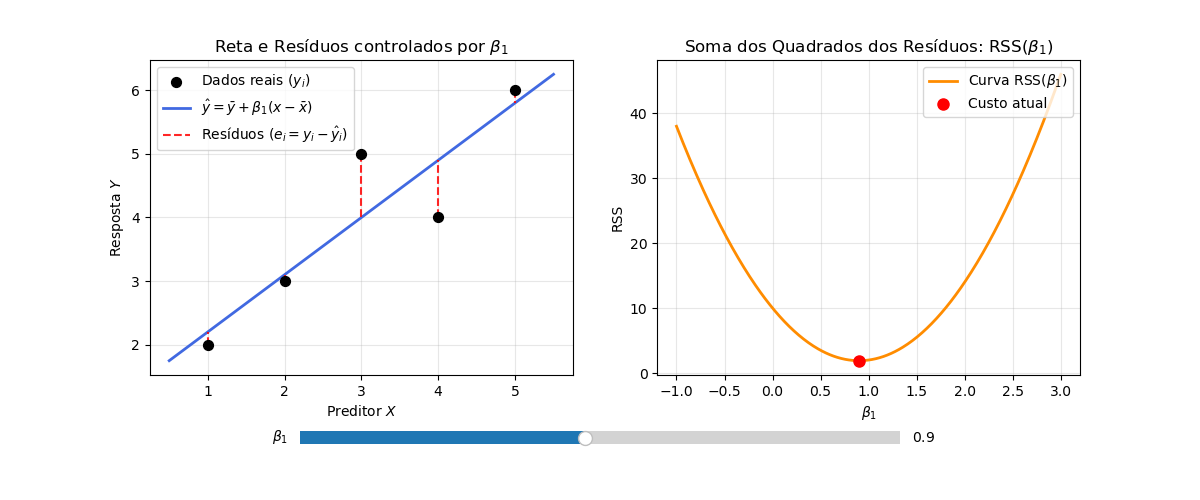

In [2]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider

# gera os dados
x = np.array([1, 2, 3, 4, 5], dtype=float)
y = np.array([2, 3, 5, 4, 6], dtype=float)

# centraliza / normaliza - ainda veremos a justificativa em aulas futuras
x_c = x - x.mean()
y_c = y - y.mean()


# RSS / SSE(beta1)

def rss(b1):
    return np.sum((y_c - b1 * x_c) ** 2)

# solução ótima
b1_hat = np.sum(x_c * y_c) / np.sum(x_c ** 2)

# códigos dos gráfics
b1_vals = np.linspace(-1, 3, 400)
rss_vals = [rss(b) for b in b1_vals]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
plt.subplots_adjust(bottom=0.25)

ax1.scatter(x, y, color='black', s=50, zorder=3, label='Dados reais ($y_i$)')
x_line = np.linspace(x.min() - 0.5, x.max() + 0.5, 100)

(line,) = ax1.plot(
    x_line, 
    y.mean() + b1_hat * (x_line - x.mean()), 
    color='royalblue', 
    linewidth=2,
    label=r'$\hat{y} = \bar{y} + \beta_1(x - \bar{x})$'
)

y_pred_init = y.mean() + b1_hat * x_c
res_lines = []
for xi, yi, y_hat_i in zip(x, y, y_pred_init):
    (r_line,) = ax1.plot(
        [xi, xi], [yi, y_hat_i], 
        color='red', 
        linestyle='--', 
        linewidth=1.5, 
        alpha=0.85
    )
    res_lines.append(r_line)

res_lines[0].set_label(r'Resíduos ($e_i = y_i - \hat{y}_i$)')

ax1.set_title("Reta e Resíduos controlados por $\\beta_1$")
ax1.set_xlabel("Preditor $X$")
ax1.set_ylabel("Resposta $Y$")
ax1.grid(alpha=0.3)
ax1.legend(loc="upper left")

#  Curva de Custo RSS
ax2.plot(b1_vals, rss_vals, color='darkorange', linewidth=2, label='Curva RSS($\\beta_1$)')
(point,) = ax2.plot([b1_hat], [rss(b1_hat)], 'ro', markersize=8, label='Custo atual')

ax2.set_title("Soma dos Quadrados dos Resíduos: $\\text{RSS}(\\beta_1)$")
ax2.set_xlabel(r"$\beta_1$")
ax2.set_ylabel("RSS")
ax2.grid(alpha=0.3)
ax2.legend(loc="upper right")

# Slider Interativo
ax_slider = plt.axes([0.25, 0.1, 0.5, 0.05])
slider = Slider(ax_slider, r"$\beta_1$", -1.0, 3.0, valinit=b1_hat, valstep=0.02)

def update(val):
    b1 = slider.val

    # 1. Atualiza a reta
    y_hat_line = y.mean() + b1 * (x_line - x.mean())
    line.set_ydata(y_hat_line)

    # 2. Atualiza a posição de cada segmento tracejado de resíduo
    y_pred_pts = y.mean() + b1 * x_c
    for r_line, xi, yi, y_hat_i in zip(res_lines, x, y, y_pred_pts):
        r_line.set_data([xi, xi], [yi, y_hat_i])

    # 3. Atualiza o ponto na parábola de RSS
    point.set_data([b1], [rss(b1)])

    fig.canvas.draw_idle()

slider.on_changed(update)

plt.show()

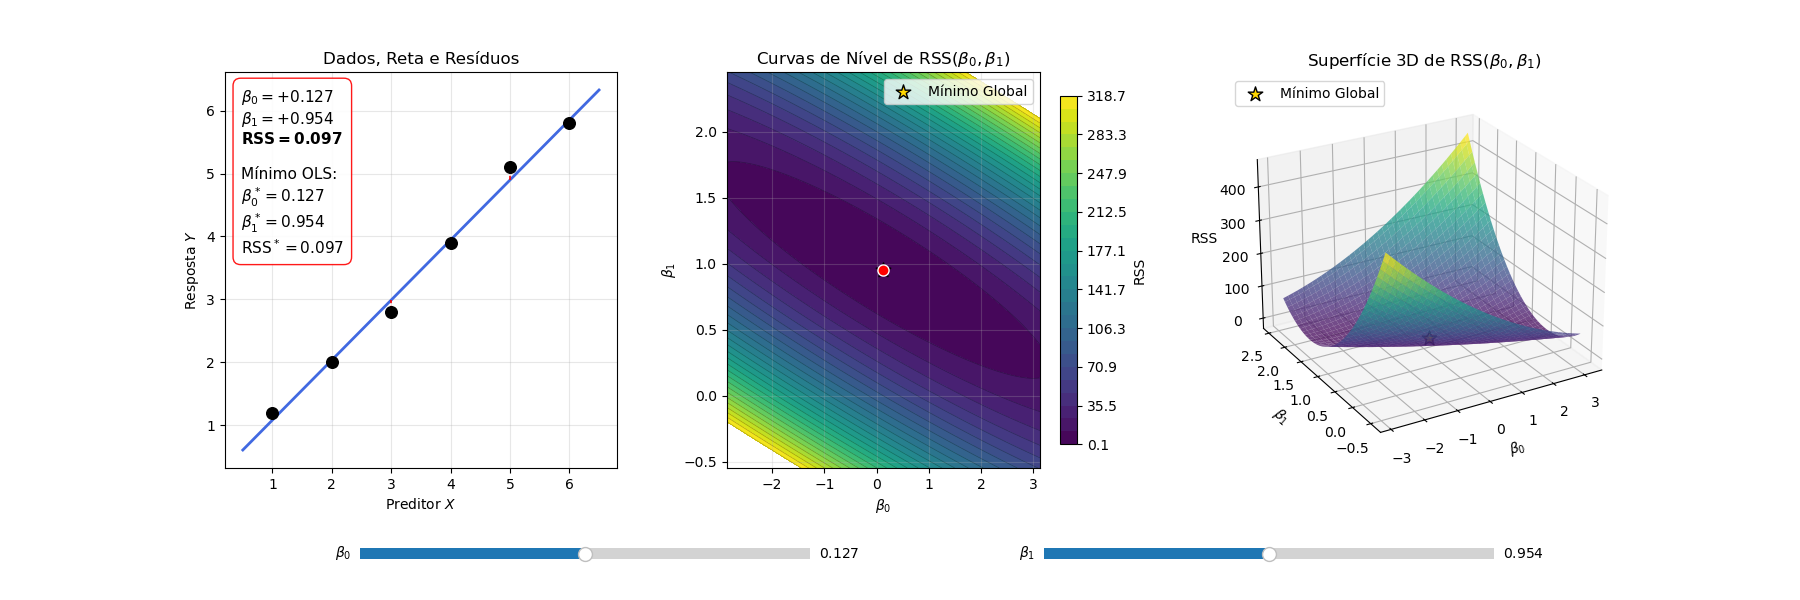

In [3]:
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
import numpy as np


# Dados e Ajuste OLS / mínimos quadrados

x = np.array([1, 2, 3, 4, 5, 6], dtype=float)
y = np.array([1.2, 2.0, 2.8, 3.9, 5.1, 5.8], dtype=float)


def rss(b0, b1):
  return np.sum((y - (b0 + b1 * x)) ** 2)


x_bar = x.mean()
y_bar = y.mean()

b1_hat = np.sum((x - x_bar) * (y - y_bar)) / np.sum((x - x_bar) ** 2)
b0_hat = y_bar - b1_hat * x_bar
rss_hat = rss(b0_hat, b1_hat)


# Grade para RSS(beta0, beta1)

b0_vals = np.linspace(b0_hat - 3.0, b0_hat + 3.0, 120)
b1_vals = np.linspace(b1_hat - 1.5, b1_hat + 1.5, 120)

B0, B1 = np.meshgrid(b0_vals, b1_vals)
Z = np.zeros_like(B0)

for i in range(B0.shape[0]):
  for j in range(B0.shape[1]):
    Z[i, j] = rss(B0[i, j], B1[i, j])


# charts code

fig = plt.figure(figsize=(18, 6))
fig.subplots_adjust(bottom=0.22, wspace=0.28)

ax_data = fig.add_subplot(1, 3, 1)
ax_contour = fig.add_subplot(1, 3, 2)
ax_3d = fig.add_subplot(1, 3, 3, projection="3d")

# parte 1: Reta e Resíduos
ax_data.scatter(x, y, s=70, color="black", zorder=3)
x_line = np.linspace(x.min() - 0.5, x.max() + 0.5, 200)
(line_data,) = ax_data.plot(
    x_line, b0_hat + b1_hat * x_line, color="royalblue", linewidth=2
)

residual_lines = []
for xi, yi in zip(x, y):
  yhi = b0_hat + b1_hat * xi
  (ln,) = ax_data.plot(
      [xi, xi], [yi, yhi], color="red", linestyle="--", linewidth=1.2
  )
  residual_lines.append(ln)

hud_text = ax_data.text(
    0.04,
    0.96,
    "",
    transform=ax_data.transAxes,
    va="top",
    ha="left",
    fontsize=11,
    bbox=dict(
        boxstyle="round,pad=0.5", facecolor="white", edgecolor="red", alpha=0.9
    ),
)

ax_data.set_title("Dados, Reta e Resíduos")
ax_data.set_xlabel("Preditor $X$")
ax_data.set_ylabel("Resposta $Y$")
ax_data.grid(alpha=0.3)

# curvas de Nível - painel 2
levels = np.linspace(Z.min(), np.percentile(Z, 97), 28)
cf = ax_contour.contourf(B0, B1, Z, levels=levels, cmap="viridis")
ax_contour.contour(
    B0, B1, Z, levels=levels, linewidths=0.5, colors="black", alpha=0.3
)

ax_contour.scatter(
    b0_hat,
    b1_hat,
    s=120,
    marker="*",
    color="gold",
    edgecolors="black",
    zorder=5,
    label="Mínimo Global",
)
(point_2d,) = ax_contour.plot(
    [b0_hat],
    [b1_hat],
    "ro",
    markersize=8,
    markeredgecolor="white",
    zorder=6,
)

ax_contour.set_title(r"Curvas de Nível de $\text{RSS}(\beta_0, \beta_1)$")
ax_contour.set_xlabel(r"$\beta_0$")
ax_contour.set_ylabel(r"$\beta_1$")
ax_contour.legend(loc="upper right")
ax_contour.grid(alpha=0.25)

cbar = fig.colorbar(cf, ax=ax_contour, shrink=0.88)
cbar.set_label("RSS")

# painel 3: superfície 3D - nesse caso temos um mínimo global
surf = ax_3d.plot_surface(
    B0, B1, Z, cmap="viridis", alpha=0.75, edgecolor="none"
)
ax_3d.scatter(
    [b0_hat],
    [b1_hat],
    [rss_hat],
    s=120,
    marker="*",
    color="gold",
    edgecolors="black",
    label="Mínimo Global",
)
(point_3d,) = ax_3d.plot(
    [b0_hat], [b1_hat], [rss_hat], "ro", markersize=8, markeredgecolor="white"
)

ax_3d.set_title(r"Superfície 3D de $\text{RSS}(\beta_0, \beta_1)$")
ax_3d.set_xlabel(r"$\beta_0$")
ax_3d.set_ylabel(r"$\beta_1$")
ax_3d.set_zlabel("RSS")
ax_3d.view_init(elev=25, azim=-120)
ax_3d.legend(loc="upper left")


# Sliders Interativos
ax_slider_b0 = plt.axes([0.20, 0.06, 0.25, 0.035])
ax_slider_b1 = plt.axes([0.58, 0.06, 0.25, 0.035])

slider_b0 = Slider(
    ax_slider_b0,
    r"$\beta_0$",
    b0_vals.min(),
    b0_vals.max(),
    valinit=b0_hat,
    valstep=0.02,
)
slider_b1 = Slider(
    ax_slider_b1,
    r"$\beta_1$",
    b1_vals.min(),
    b1_vals.max(),
    valinit=b1_hat,
    valstep=0.02,
)


def update(_):
  b0 = slider_b0.val
  b1 = slider_b1.val
  current_rss = rss(b0, b1)

  # Reta
  y_line = b0 + b1 * x_line
  line_data.set_ydata(y_line)

  #  Resíduos
  for ln, xi, yi in zip(residual_lines, x, y):
    yhi = b0 + b1 * xi
    ln.set_data([xi, xi], [yi, yhi])

  #  Ponto 2D
  point_2d.set_data([b0], [b1])

  #  Ponto 3D
  point_3d.set_data([b0], [b1])
  point_3d.set_3d_properties([current_rss])

  #  Atualização exclusiva do texto HUD
  hud_text.set_text(
      f"$\\beta_0 = {b0:+.3f}$\n"
      f"$\\beta_1 = {b1:+.3f}$\n"
      f"$\\mathbf{{RSS = {current_rss:.3f}}}$\n\n"
      f"Mínimo OLS:\n"
      f"$\\beta_0^* = {b0_hat:.3f}$\n"
      f"$\\beta_1^* = {b1_hat:.3f}$\n"
      f"$\\text{{RSS}}^* = {rss_hat:.3f}$"
  )

  fig.canvas.draw_idle()


slider_b0.on_changed(update)
slider_b1.on_changed(update)

update(None)
plt.show()

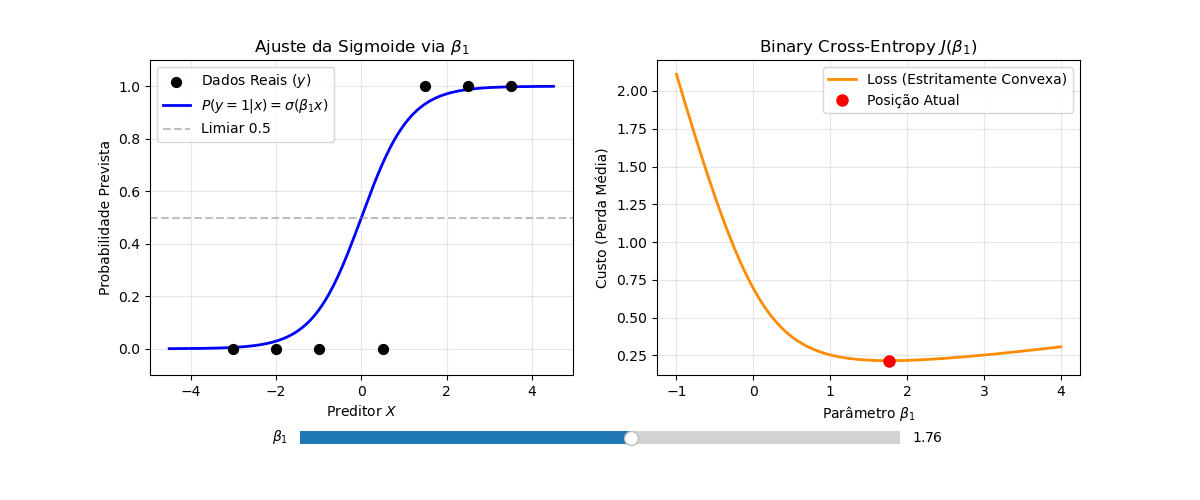

In [4]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider


# dados didáticos (ex: Horas de estudo vs Aprovação)

x = np.array([-3, -2, -1, 0.5, 1.5, 2.5, 3.5], dtype=float)
y = np.array([0, 0, 0, 0, 1, 1, 1], dtype=float)
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def bce_loss(b1, b0=0.0):
    # p = probabilidade prevista pela sigmoide
    p = sigmoid(b0 + b1 * x)
    # clip para evitar log(0)
    eps = 1e-15
    p = np.clip(p, eps, 1 - eps)
    # Log-Verossimilhança Negativa média
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

# Grid de b1 para plotar a Loss Convexa
b1_vals = np.linspace(-1.0, 4.0, 300)
loss_vals = [bce_loss(b) for b in b1_vals]
b1_opt = b1_vals[np.argmin(loss_vals)]

# códigos dos gráficos

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
plt.subplots_adjust(bottom=0.25)

#  Esquerda: Dados e Sigmoide
ax1.scatter(x, y, color="black", s=50, zorder=3, label="Dados Reais ($y$)")
x_line = np.linspace(-4.5, 4.5, 200)
(line,) = ax1.plot(
    x_line,
    sigmoid(b1_opt * x_line),
    color="blue",
    linewidth=2,
    label=r"$P(y=1|x) = \sigma(\beta_1 x)$",
)
ax1.axhline(0.5, color="gray", linestyle="--", alpha=0.5, label="Limiar 0.5")
ax1.set_ylim(-0.1, 1.1)
ax1.set_title(r"Ajuste da Sigmoide via $\beta_1$")
ax1.set_xlabel("Preditor $X$")
ax1.set_ylabel("Probabilidade Prevista")
ax1.grid(alpha=0.3)
ax1.legend(loc="upper left")

#  Direita: Curva da BCE Loss
ax2.plot(
    b1_vals,
    loss_vals,
    color="darkorange",
    linewidth=2,
    label="Loss (Estritamente Convexa)",
)
(point,) = ax2.plot(
    [b1_opt], [bce_loss(b1_opt)], "ro", markersize=8, label="Posição Atual"
)
ax2.set_title(r"Binary Cross-Entropy $J(\beta_1)$")
ax2.set_xlabel(r"Parâmetro $\beta_1$")
ax2.set_ylabel("Custo (Perda Média)")
ax2.grid(alpha=0.3)
ax2.legend(loc="upper right")

# slide interativo
ax_slider = plt.axes([0.25, 0.1, 0.5, 0.05])
slider = Slider(
    ax_slider, r"$\beta_1$", -1.0, 4.0, valinit=b1_opt, valstep=0.02
)

def update(val):
    b1 = slider.val

    # para curva sigmoide
    p_line = sigmoid(b1 * x_line)
    line.set_ydata(p_line)

    # para o ponto na curva de perda
    point.set_data([b1], [bce_loss(b1)])

    fig.canvas.draw_idle()


slider.on_changed(update)
plt.show()

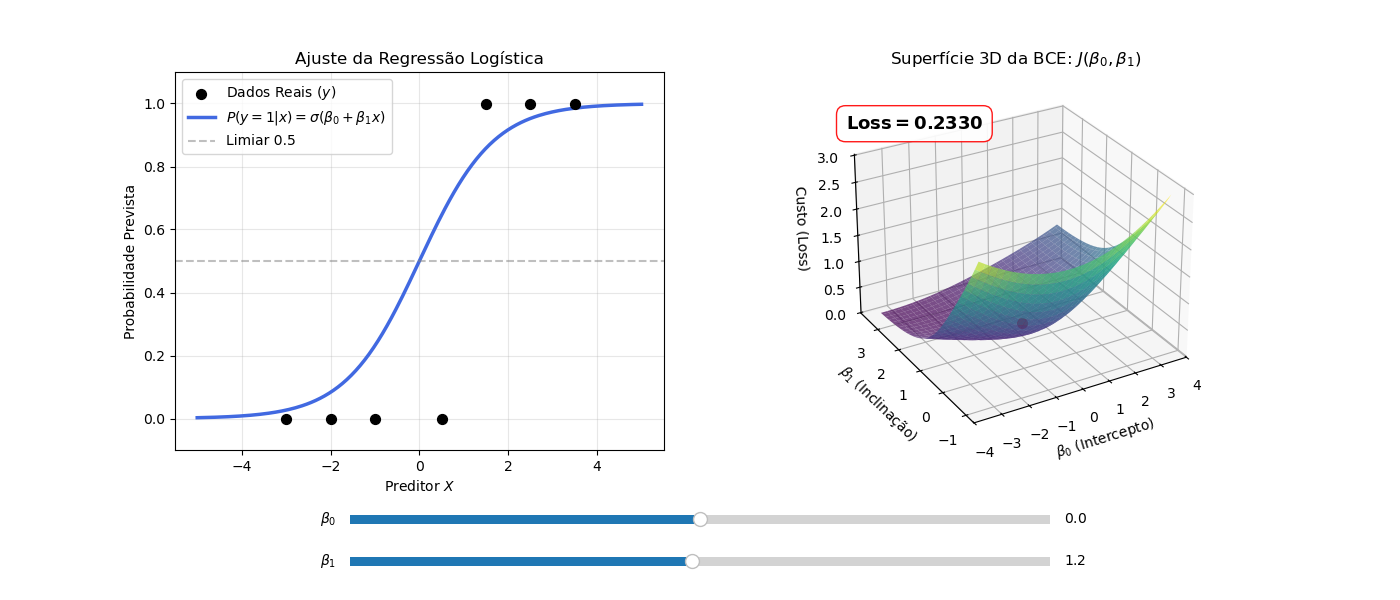

In [5]:
%matplotlib widget
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

# dados de classificação binária

x = np.array([-3.0, -2.0, -1.0, 0.5, 1.5, 2.5, 3.5], dtype=float)
y = np.array([0, 0, 0, 0, 1, 1, 1], dtype=float)


def sigmoid(z):
  return 1.0 / (1.0 + np.exp(-z))


def bce_loss(b0, b1):
  p = sigmoid(b0 + b1 * x)
  eps = 1e-15
  p = np.clip(p, eps, 1.0 - eps)
  return -np.mean(y * np.log(p) + (1.0 - y) * np.log(1.0 - p))


bce_grid_func = np.vectorize(bce_loss)


#  Função de Custo (BCE)

b0_range = np.linspace(-3.5, 3.5, 60)
b1_range = np.linspace(-1.0, 3.5, 60)
B0, B1 = np.meshgrid(b0_range, b1_range)
Z_loss = bce_grid_func(B0, B1)

# Valores iniciais
b0_init = 0.0
b1_init = 1.2
z_init = bce_loss(b0_init, b1_init)


# códigos dos graficos

fig = plt.figure(figsize=(14, 6))
plt.subplots_adjust(bottom=0.25, wspace=0.22)

# --- Painel 1: Ajuste da Curva Sigmoide (2D) ---
ax1 = fig.add_subplot(1, 2, 1)
ax1.scatter(x, y, color='black', s=50, zorder=3, label='Dados Reais ($y$)')
x_line = np.linspace(-5.0, 5.0, 200)
(line,) = ax1.plot(
    x_line,
    sigmoid(b0_init + b1_init * x_line),
    color='royalblue',
    linewidth=2.5,
    label=r'$P(y=1|x) = \sigma(\beta_0 + \beta_1 x)$',
)
ax1.axhline(0.5, color='gray', linestyle='--', alpha=0.5, label='Limiar 0.5')
ax1.set_ylim(-0.1, 1.1)
ax1.set_title('Ajuste da Regressão Logística', fontsize=12)
ax1.set_xlabel('Preditor $X$')
ax1.set_ylabel('Probabilidade Prevista')
ax1.grid(alpha=0.3)
ax1.legend(loc='upper left')

# --- Painel 2: Superfície 3D da BCE Loss ---
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
surf = ax2.plot_surface(
    B0, B1, Z_loss, cmap='viridis', alpha=0.70, edgecolor='none'
)

# Ponto 3D inicial que se move pela superfície
(point_3d,) = ax2.plot(
    [b0_init],
    [b1_init],
    [z_init],
    color='red',
    marker='o',
    markersize=9,
    markeredgecolor='white',
)

ax2.set_title(r'Superfície 3D da BCE: $J(\beta_0, \beta_1)$', fontsize=12)
ax2.set_xlabel(r'$\beta_0$ (Intercepto)')
ax2.set_ylabel(r'$\beta_1$ (Inclinação)')
ax2.set_zlabel('Custo (Loss)')
ax2.view_init(elev=28, azim=-120)


hud_text = ax2.text2D(
    0.05,
    0.85,
    f'$\\mathbf{{Loss = {z_init:.4f}}}$',
    transform=ax2.transAxes,
    fontsize=13,
    bbox=dict(
        boxstyle='round,pad=0.5', facecolor='white', edgecolor='red', alpha=0.9
    ),
)


# Sliders Interativos

ax_slider_b0 = plt.axes([0.25, 0.12, 0.50, 0.03])
ax_slider_b1 = plt.axes([0.25, 0.05, 0.50, 0.03])

slider_b0 = Slider(
    ax_slider_b0, r'$\beta_0$', -3.5, 3.5, valinit=b0_init, valstep=0.05
)
slider_b1 = Slider(
    ax_slider_b1, r'$\beta_1$', -1.0, 3.5, valinit=b1_init, valstep=0.05
)


def update(val):
  b0 = slider_b0.val
  b1 = slider_b1.val
  loss_val = bce_loss(b0, b1)

  # Atualiza a curva da sigmoide
  p_line = sigmoid(b0 + b1 * x_line)
  line.set_ydata(p_line)

  # Atualiza a posição da bolinha 3D
  point_3d.set_data([b0], [b1])
  point_3d.set_3d_properties([loss_val])

  # Atualiza apenas o texto do cartão HUD
  hud_text.set_text(f'$\\mathbf{{Loss = {loss_val:.4f}}}$')

  fig.canvas.draw_idle()


slider_b0.on_changed(update)
slider_b1.on_changed(update)

plt.show()